## InterferometryResponse 

This notebook defines the `InterferometryResponse` class, a custom linear operator used for simulating and inverting interferometric measurements in image reconstruction workflows. It uses the [ducc0.wgridder](https://gitlab.mpcdf.mpg.de/mtr/ducc) library for efficient (de)gridding.

### Mathematical Overview

The forward interferometric measurement process is modeled by the van Cittert–Zernike theorem:

$$
V(u, v) = \iint I(l, m) \, e^{-2\pi i (ul + vm)} \, dl \, dm
$$

This class provides:
- **Forward transform**: Image → Visibilities
- **Adjoint transform**: Visibilities → Image (dirty map)

It wraps these transformations using NIFTy’s `LinearOperator` interface.

---

### Parameters

| Parameter    | Type           | Description |
|--------------|----------------|-------------|
| `domain`     | `DomainTuple`  | NIFTy domain of the image (typically an `RGSpace`). |
| `data`       | `dict`         | Dictionary of observational data (see below). |
| `epsilon`    | `float`        | Desired accuracy for NUFFT kernel in ducc0. |
| `normalize`  | `bool`         | Normalize the response by FFT volume (default `False`). |
| `scaling`    | `bool`         | Whether to apply Jacobian-like scaling in adjoint (default `False`). |

---

### Required Keys in `data` Dictionary

| Key      | Type       | Description |
|----------|------------|-------------|
| `nbl`    | `int`      | Number of baselines. |
| `uco`    | `(nbl,1)`  | U-coordinates (wavelengths). |
| `vco`    | `(nbl,1)`  | V-coordinates (wavelengths). |
| `freq`   | `ndarray`  | Frequency array (Hz). |


In [1]:
#| default_exp InterferometryResponse

In [2]:
#| export

import ducc0.wgridder as ng
import numpy as np
import nifty8 as ift

class InterferometryResponse(ift.LinearOperator):
    """
    A linear operator modeling interferometric observations using non-uniform FFT
    via the ducc0 wgridder backend.
    """
    def __init__(self, domain, data, epsilon, normalize=False, scaling = False):
        
        self._normalize = normalize
        self.scaling = scaling
        # 1.) Define UV-coordinates
        self._nframe = data['nbl']
        self._uvw = np.zeros((self._nframe, 3))

        # Load visibility uv-coordinates
        self._uvw[:, 0] = data['uco'].ravel()  # u-coordinates
        self._uvw[:, 1] = data['vco'].ravel()  # v-coordinates
        
        SPEEDOFLIGHT = 299792458.0  # Speed of light in m/s

        self._freq = np.array(data['freq'], dtype=np.float64)
        self._eps = float(epsilon)

        # 3.) Define operator domain and target space
        self._domain = ift.makeDomain(domain)
        #self._target = ift.DomainTuple.make([ift.UnstructuredDomain(data['nbl'])])
        self._target = ift.DomainTuple.make([ift.UnstructuredDomain((data['nbl'], 1))])
        self._capability = self.TIMES | self.ADJOINT_TIMES

    def apply(self, x, mode):
        self._check_input(x, mode)
        dx, dy = self._domain[0].distances
        nx, ny = self._domain[0].shape

        if mode == self.TIMES:
            # Forward operator: Image -> Visibilities
            res = np.full(self._target.shape, np.nan, dtype=np.complex128)
            
            # Compute Fourier transform using dirty2ms
            resRE = ng.dirty2ms(self._uvw, self._freq, np.real(x.val), None, dx, dy, 0, 0, self._eps, False)
            resIM = ng.dirty2ms(self._uvw, self._freq, np.imag(x.val), None, dx, dy, 0, 0, self._eps, False)
            res = (resRE + 1j * resIM)

        else:
            # Adjoint operator: Visibilities -> Image
            res = np.zeros(self._domain[0].shape, dtype=np.complex128)            
            xx = np.asarray(x.val, dtype=np.complex128)
            resRE = ng.ms2dirty(self._uvw, self._freq, xx, None, nx, ny, dx, dy, 0, 0, self._eps, False)
            resIM = ng.ms2dirty(self._uvw, self._freq, -1j * xx, None, nx, ny, dx, dy, 0, 0, self._eps, False)
            res = resRE + 1j * resIM
        
        if self.scaling:
            # Apply scaling factor
            res *= self._domain[0].scalar_dvol
            
        if self._normalize:
            # Normalize the result
            maxval = np.max(np.abs(res))
            if maxval > 0 and np.isfinite(maxval):
                res /= maxval
            
        return ift.makeField(self._tgt(mode), res)

This is a `LinearOperator` subclass and does **not return values directly** upon instantiation.

When used in **forward mode** (`R(x)`), it returns:

- **Complex visibilities** of shape `(nbl, 1)` for input image `x`.

When used in **adjoint mode** (`R.adjoint(y)`), it returns:

- A **dirty image** field on the same domain as `x`, from visibilities `y`.

---


### Example: forward model, dirty image and adjoint test

Apply the operator to a simple Gaussian sky, form the dirty image with the adjoint, and check
that `R` and `R.adjoint` are consistent with NIFTy's `check_linear_operator`.

dot test relative error: 3.2e-16


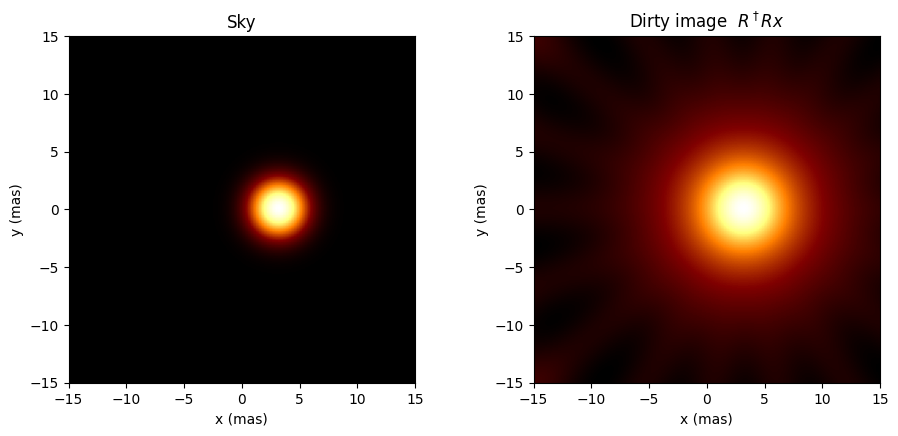

In [3]:
import matplotlib.pyplot as plt
from nifty_oi.dataload import read_data
from nifty_oi import sky_models as sky

data = read_data('../data/Gaussian_elong.fits')
npix, fov_mas = 128, 30
L, M, dx = sky.make_coordinate_grid(npix, fov_mas)
space = ift.RGSpace((npix, npix), (dx, dx))
R = InterferometryResponse(space, {'nbl': data['nbl'], 'uco': data['uco'], 'vco': data['vco'], 'freq': data['freq']}, 1e-8)

x = ift.makeField(R.domain, sky.make_gaussian(L, M, fwhm_mas=4.0, x0_mas=3.0))
vis = R(x)
dirty = R.adjoint(vis)
# adjoint (dot-product) test: <y, R x> == <R^H y, x>
y = ift.from_random(R.target, dtype=np.complex128)
lhs, rhs = np.vdot(y.val, R(x).val), np.vdot(R.adjoint(y).val, x.val)
print(f"dot test relative error: {abs(lhs - rhs) / abs(lhs):.1e}")
ift.extra.check_linear_operator(R, np.float64, np.complex128, atol=1e-6, rtol=1e-6)  # gridder accuracy ~ epsilon

ext = [-fov_mas/2, fov_mas/2, -fov_mas/2, fov_mas/2]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].imshow(x.val.T, origin='lower', extent=ext, cmap='afmhot'); axs[0].set_title('Sky')
axs[1].imshow(dirty.val.real.T, origin='lower', extent=ext, cmap='afmhot'); axs[1].set_title('Dirty image  $R^\\dagger R x$')
for a in axs: a.set_xlabel('x (mas)'); a.set_ylabel('y (mas)')
plt.show()